# 📊 Phase 2 CRISP-DM : Data Understanding
## Projet de Fin d'Études — Automatisation du Processus KYC

---

Ce notebook présente l'analyse exploratoire complète du jeu de données synthétique généré pour le projet KYC.  
L'objectif est de comprendre la **composition**, la **distribution** et les **caractéristiques statistiques** des données avant de passer à la modélisation.

> **Jeu de données** : Documents synthétiques générés à partir de templates réels (CIN, Fiches de Paie, Factures STEG),  
> associés à des profils clients insérés dans la base de données Core Banking System (CBS).

## 0. Importation des bibliothèques

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import mysql.connector
from PIL import Image

# Affichage inline dans le notebook
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

print('Bibliothèques chargées avec succès.')

Bibliothèques chargées avec succès.


## 1. Configuration des chemins et constantes

In [2]:
DATASET_DIR = r"D:\PFE\dataset_synthetique_masse"
DB_CONFIG   = dict(host='localhost', user='root', password='', database='cbs_kyc')

# Palette de couleurs cohérente
COLORS = {
    'cin'   : '#4E79A7',
    'paie1' : '#F28E2B',
    'paie2' : '#E15759',
    'steg'  : '#76B7B2',
    'grid'  : '#F0F0F0',
    'text'  : '#333333',
}

print(f'Dossier dataset : {DATASET_DIR}')
print(f'Fichiers présents : {len(os.listdir(DATASET_DIR))} documents')

Dossier dataset : D:\PFE\dataset_synthetique_masse
Fichiers présents : 2100 documents


---
## 2. Analyse du Jeu de Données (Dossier)

On commence par **compter** les documents par type et **calculer** leurs caractéristiques physiques (taille, dimensions).

In [3]:
counts     = {'CIN': 0, 'Fiche de Paie (T1)': 0, 'Fiche de Paie (T2)': 0, 'Facture STEG': 0}
tailles_ko = {'CIN': [], 'Fiche de Paie (T1)': [], 'Fiche de Paie (T2)': [], 'Facture STEG': []}

for fname in os.listdir(DATASET_DIR):
    fpath = os.path.join(DATASET_DIR, fname)
    if not os.path.isfile(fpath):
        continue
    size_ko = os.path.getsize(fpath) / 1024
    if fname.startswith('cin_mass'):
        key = 'CIN'
    elif fname.startswith('paie_mass') or fname.startswith('paie2_mass_exist'):
        key = 'Fiche de Paie (T1)'
    elif fname.startswith('paie2_mass_new'):
        key = 'Fiche de Paie (T2)'
    elif fname.startswith('steg_mass'):
        key = 'Facture STEG'
    else:
        continue
    counts[key]     += 1
    tailles_ko[key].append(size_ko)

total = sum(counts.values())
print(f'Total documents : {total:,}')
print('-' * 50)
for k, v in counts.items():
    moy = f"{np.mean(tailles_ko[k]):.1f} Ko" if tailles_ko[k] else 'N/A'
    print(f'  {k:<22}: {v:>5} docs  |  Taille moy : {moy}')

Total documents : 2,100
--------------------------------------------------
  CIN                   :   300 docs  |  Taille moy : 48.3 Ko
  Fiche de Paie (T1)    :   900 docs  |  Taille moy : 198.3 Ko
  Fiche de Paie (T2)    :   300 docs  |  Taille moy : 96.8 Ko
  Facture STEG          :   600 docs  |  Taille moy : 306.4 Ko


### 2.1 Répartition des documents par type

Le graphique ci-dessous présente la **distribution du jeu de données** sous forme de camembert et d'histogramme.

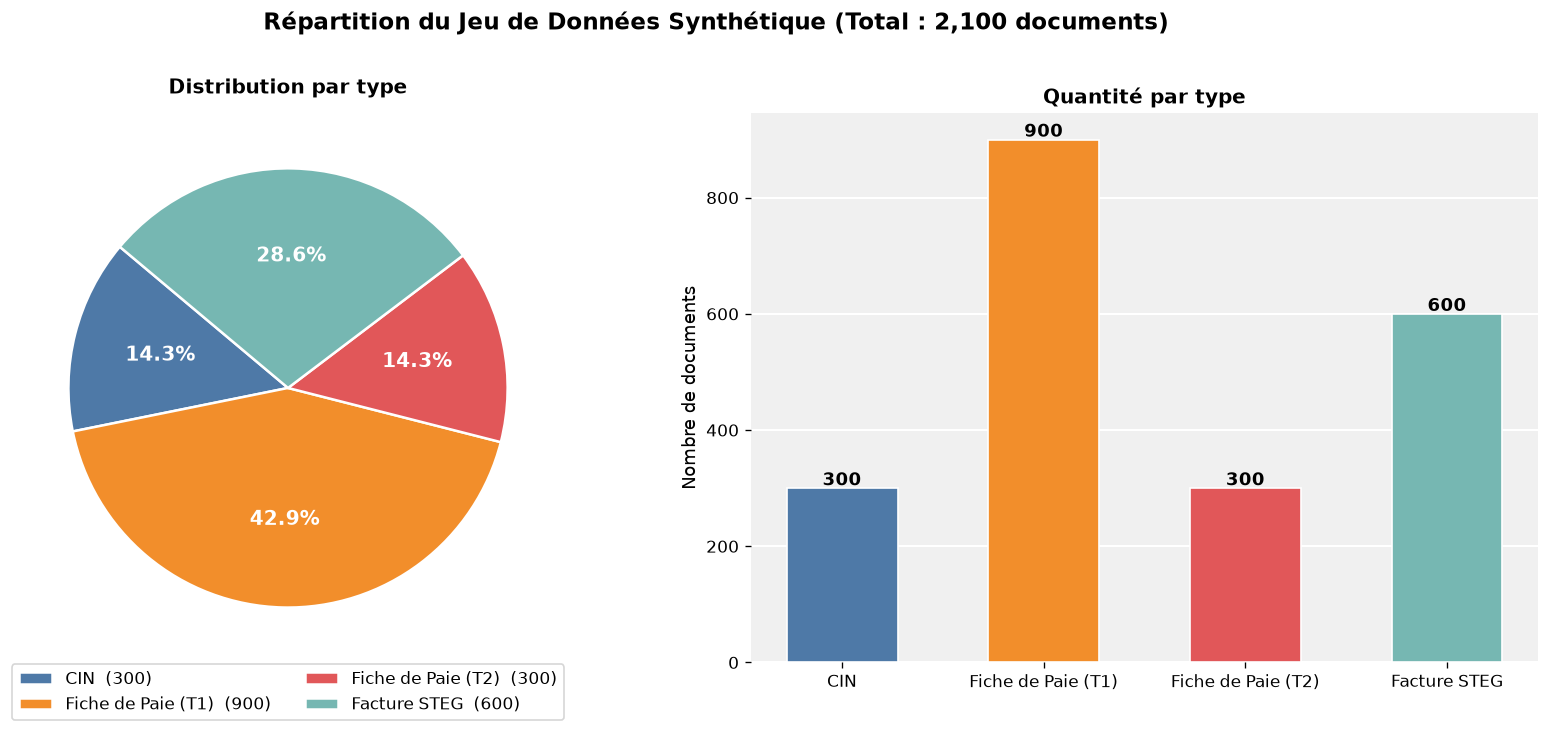

In [4]:
labels   = list(counts.keys())
values   = list(counts.values())
couleurs = [COLORS['cin'], COLORS['paie1'], COLORS['paie2'], COLORS['steg']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('white')
fig.suptitle(f'Répartition du Jeu de Données Synthétique (Total : {total:,} documents)',
             fontsize=14, fontweight='bold', y=1.01)

# Pie Chart
wedges, texts, autotexts = ax1.pie(
    values, colors=couleurs, autopct='%1.1f%%', startangle=140,
    wedgeprops=dict(linewidth=1.5, edgecolor='white')
)
for at in autotexts:
    at.set_fontweight('bold'); at.set_color('white'); at.set_fontsize(12)
ax1.legend(wedges, [f"{l}  ({v:,})" for l, v in zip(labels, values)],
           loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=10)
ax1.set_title('Distribution par type', fontsize=12, fontweight='bold', pad=12)

# Bar Chart
bars = ax2.bar(labels, values, color=couleurs, edgecolor='white', width=0.55)
ax2.set_facecolor(COLORS['grid'])
ax2.yaxis.grid(True, color='white', linewidth=1.2)
ax2.set_axisbelow(True)
ax2.set_ylabel('Nombre de documents', fontsize=11)
ax2.set_title('Quantité par type', fontsize=12, fontweight='bold')
ax2.spines[['top','right','left','bottom']].set_visible(False)
for bar, val in zip(bars, values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             f'{val:,}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

**Commentaire :** Le jeu de données est dominé par les Fiches de Paie (Type 1) qui représentent la majorité des documents. Les CIN et les Factures STEG complètent l'ensemble, permettant de simuler un dossier KYC complet.

### 2.2 Distribution de la taille des fichiers

Ce box-plot permet de visualiser la **variabilité de la taille** des images pour chaque type de document.

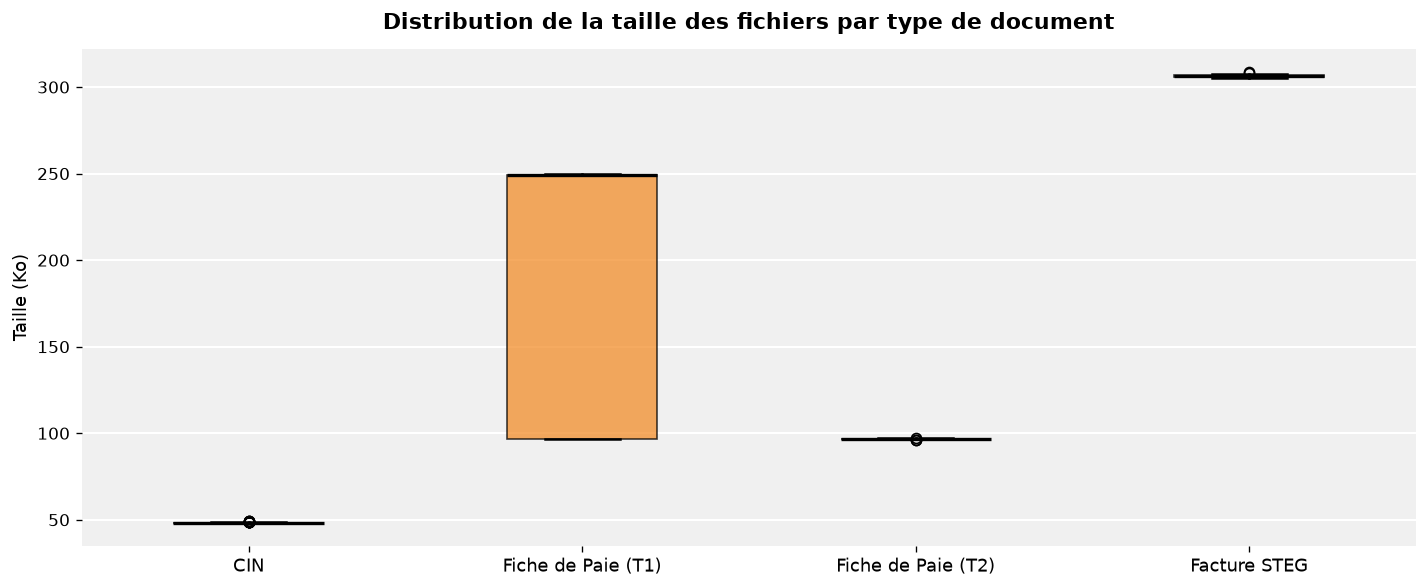

Statistiques de taille (Ko) :
  CIN                   : min=47.9  max=49.2  moy=48.3  std=0.2
  Fiche de Paie (T1)    : min=96.4  max=249.7  moy=198.3  std=71.8
  Fiche de Paie (T2)    : min=96.3  max=97.3  moy=96.8  std=0.2
  Facture STEG          : min=305.2  max=308.9  moy=306.4  std=0.5


In [5]:
data_f   = {k: v for k, v in tailles_ko.items() if v}
keys     = list(data_f.keys())
vals     = [data_f[k] for k in keys]
cols     = couleurs[:len(keys)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_facecolor(COLORS['grid'])
bp = ax.boxplot(vals, patch_artist=True,
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(linewidth=1.5),
                capprops=dict(linewidth=1.5))
for patch, color in zip(bp['boxes'], cols):
    patch.set_facecolor(color); patch.set_alpha(0.75)

ax.set_xticklabels(keys, fontsize=11)
ax.set_ylabel('Taille (Ko)', fontsize=11)
ax.set_title('Distribution de la taille des fichiers par type de document',
             fontsize=13, fontweight='bold', pad=12)
ax.yaxis.grid(True, color='white', linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[['top','right','left','bottom']].set_visible(False)
plt.tight_layout()
plt.show()

print('Statistiques de taille (Ko) :')
for k in keys:
    arr = np.array(tailles_ko[k])
    print(f'  {k:<22}: min={arr.min():.1f}  max={arr.max():.1f}  moy={arr.mean():.1f}  std={arr.std():.1f}')

**Commentaire :** Les Factures STEG sont les images les plus lourdes (template haute résolution), tandis que les CIN sont les plus légères. Cette variabilité est normale et reflète la différence de complexité visuelle entre les types de documents.

---
## 3. Analyse de la Base de Données CBS (MySQL)

Le Core Banking System contient les profils clients associés aux documents. On analyse ici la **composition** de cette base.

In [6]:
try:
    conn   = mysql.connector.connect(**DB_CONFIG)
    cursor = conn.cursor(dictionary=True)

    cursor.execute("SELECT COUNT(*) as total FROM clients")
    total_clients = cursor.fetchone()['total']

    cursor.execute("SELECT COUNT(*) as nb FROM clients WHERE nom_ar IS NOT NULL AND nom_ar != ''")
    bilingues = cursor.fetchone()['nb']

    cursor.execute("SELECT niveau_risque, COUNT(*) as nb FROM clients GROUP BY niveau_risque")
    risque_dict = {r['niveau_risque']: r['nb'] for r in cursor.fetchall()}

    cursor.execute("SELECT statut_kyc, COUNT(*) as nb FROM clients GROUP BY statut_kyc")
    statut_dict = {r['statut_kyc']: r['nb'] for r in cursor.fetchall()}

    cursor.execute("SELECT salaire FROM clients WHERE salaire IS NOT NULL")
    salaires_list = [float(r['salaire']) for r in cursor.fetchall()]

    conn.close()
    print(f'Total clients         : {total_clients:,}')
    print(f'Clients bilingues     : {bilingues:,} ({bilingues/total_clients*100:.1f}%)')
    print(f'Niveaux de risque     : {risque_dict}')
    print(f'Statuts KYC           : {statut_dict}')
    print(f'Salaires - min/max/moy: {min(salaires_list):.0f} / {max(salaires_list):.0f} / {np.mean(salaires_list):.0f} DT')
except Exception as e:
    print(f'[ERREUR] MySQL : {e}')

Total clients         : 1,512
Clients bilingues     : 1,508 (99.7%)
Niveaux de risque     : {'Elevé': 170, 'Faible': 1045, 'Moyen': 297}
Statuts KYC           : {'Alerte Ecart': 3, 'Conforme': 14, 'Divergence Mineure': 3, 'Non Conforme': 2, 'Normal': 1490}
Salaires - min/max/moy: 0 / 3499 / 1919 DT


### 3.1 Répartition des clients par Niveau de Risque KYC

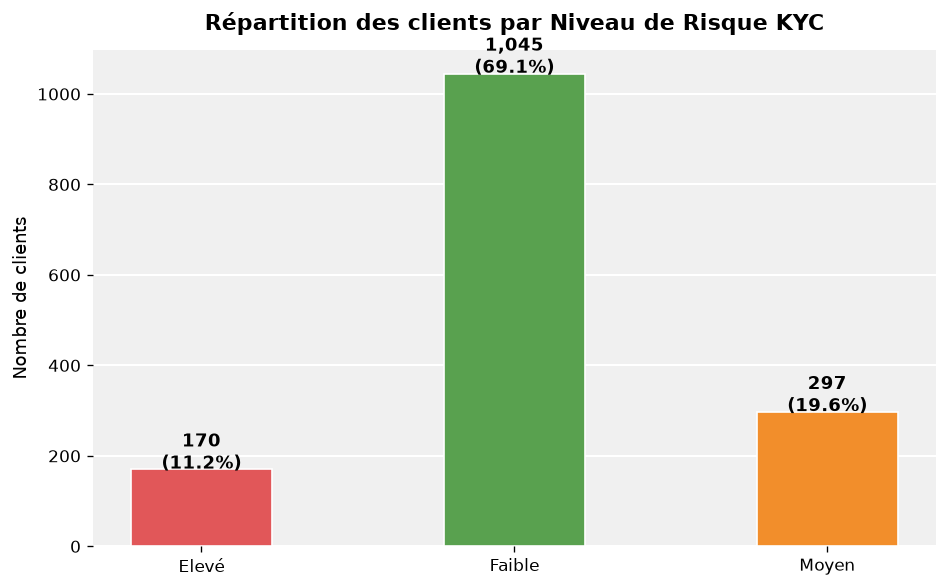

In [7]:
risk_colors = {'Faible': '#59A14F', 'Moyen': '#F28E2B', 'Elevé': '#E15759', 'Élevé': '#E15759'}
rlabels  = list(risque_dict.keys())
rvalues  = list(risque_dict.values())
rcouleurs = [risk_colors.get(l, '#999999') for l in rlabels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_facecolor(COLORS['grid'])
bars = ax.bar(rlabels, rvalues, color=rcouleurs, edgecolor='white', width=0.45)
ax.yaxis.grid(True, color='white', linewidth=1.2)
ax.set_axisbelow(True)
ax.set_ylabel('Nombre de clients', fontsize=11)
ax.set_title('Répartition des clients par Niveau de Risque KYC',
             fontsize=13, fontweight='bold', pad=12)
ax.spines[['top','right','left','bottom']].set_visible(False)
for bar, val in zip(bars, rvalues):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f'{val:,}\n({val/total_clients*100:.1f}%)',
            ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

**Commentaire :** La distribution des niveaux de risque reflète une réalité bancaire typique : la majorité des clients sont à **risque faible**, une minorité à **risque moyen**, et une très faible proportion à **risque élevé**. Cette répartition (70/20/10) a été intentionnellement simulée pour refléter les pratiques réelles du secteur bancaire tunisien.

### 3.2 Analyse de la Distribution des Salaires

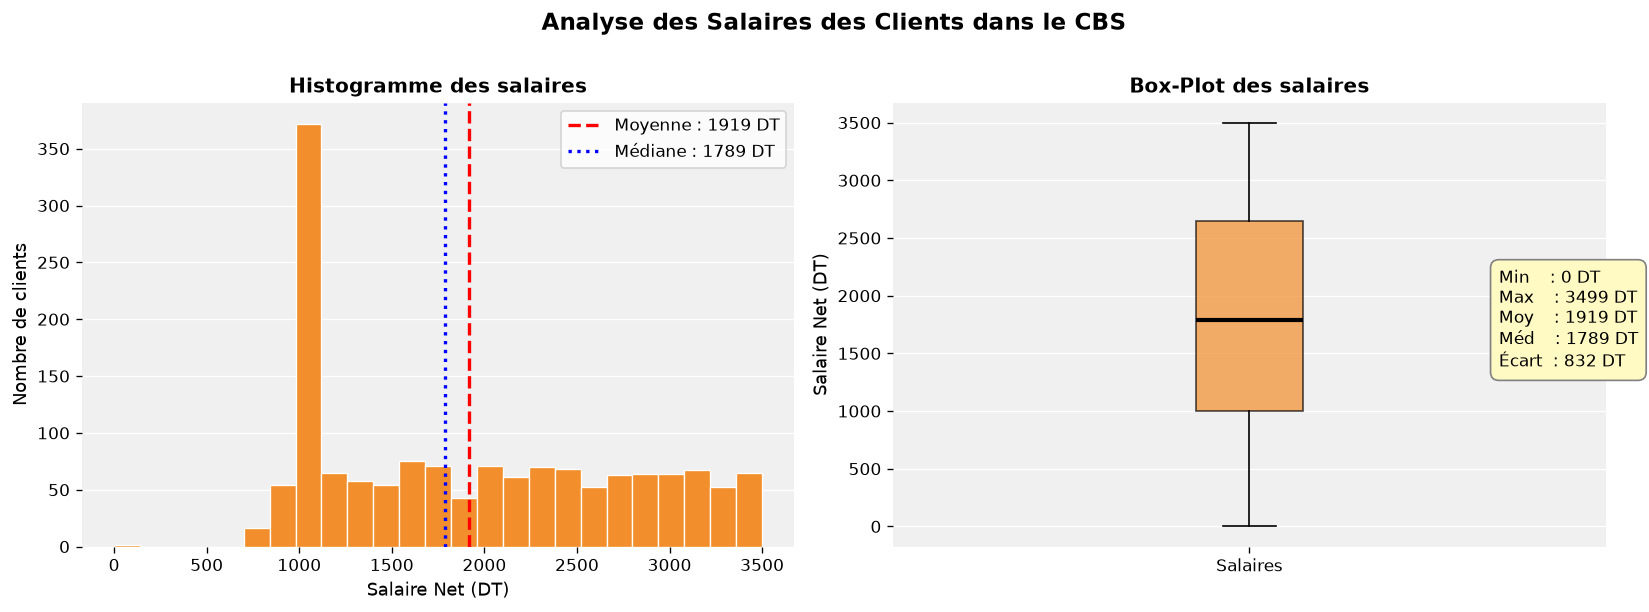

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Analyse des Salaires des Clients dans le CBS', fontsize=14, fontweight='bold', y=1.01)

# Histogramme
ax1.set_facecolor(COLORS['grid'])
ax1.hist(salaires_list, bins=25, color=COLORS['paie1'], edgecolor='white', linewidth=0.8)
ax1.axvline(np.mean(salaires_list), color='red', linewidth=2, linestyle='--',
            label=f"Moyenne : {np.mean(salaires_list):.0f} DT")
ax1.axvline(np.median(salaires_list), color='blue', linewidth=2, linestyle=':',
            label=f"Médiane : {np.median(salaires_list):.0f} DT")
ax1.set_xlabel('Salaire Net (DT)', fontsize=11)
ax1.set_ylabel('Nombre de clients', fontsize=11)
ax1.set_title('Histogramme des salaires', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.yaxis.grid(True, color='white'); ax1.set_axisbelow(True)
ax1.spines[['top','right','left','bottom']].set_visible(False)

# Box Plot
ax2.set_facecolor(COLORS['grid'])
bp = ax2.boxplot(salaires_list, patch_artist=True,
                 medianprops=dict(color='black', linewidth=2.5),
                 orientation='vertical')
bp['boxes'][0].set_facecolor(COLORS['paie1']); bp['boxes'][0].set_alpha(0.7)
ax2.set_title('Box-Plot des salaires', fontsize=12, fontweight='bold')
ax2.set_ylabel('Salaire Net (DT)', fontsize=11)
ax2.set_xticklabels(['Salaires'])
ax2.yaxis.grid(True, color='white'); ax2.set_axisbelow(True)
ax2.spines[['top','right','left','bottom']].set_visible(False)

stats_text = (
    f"Min    : {min(salaires_list):.0f} DT\n"
    f"Max    : {max(salaires_list):.0f} DT\n"
    f"Moy    : {np.mean(salaires_list):.0f} DT\n"
    f"Méd    : {np.median(salaires_list):.0f} DT\n"
    f"Écart  : {np.std(salaires_list):.0f} DT"
)
ax2.text(1.35, np.median(salaires_list), stats_text, fontsize=10, va='center',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#FFF9C4', edgecolor='gray'))

plt.tight_layout()
plt.show()

**Commentaire :** La distribution des salaires est **quasi-uniforme** entre 800 DT et 3500 DT, ce qui est cohérent avec la génération aléatoire utilisée (`random.uniform(800, 3500)`). Dans un contexte réel, on observerait plutôt une distribution asymétrique à droite (la majorité des salaires serait concentrée entre 800 et 1500 DT).

---
## 4. Tableau Récapitulatif Final

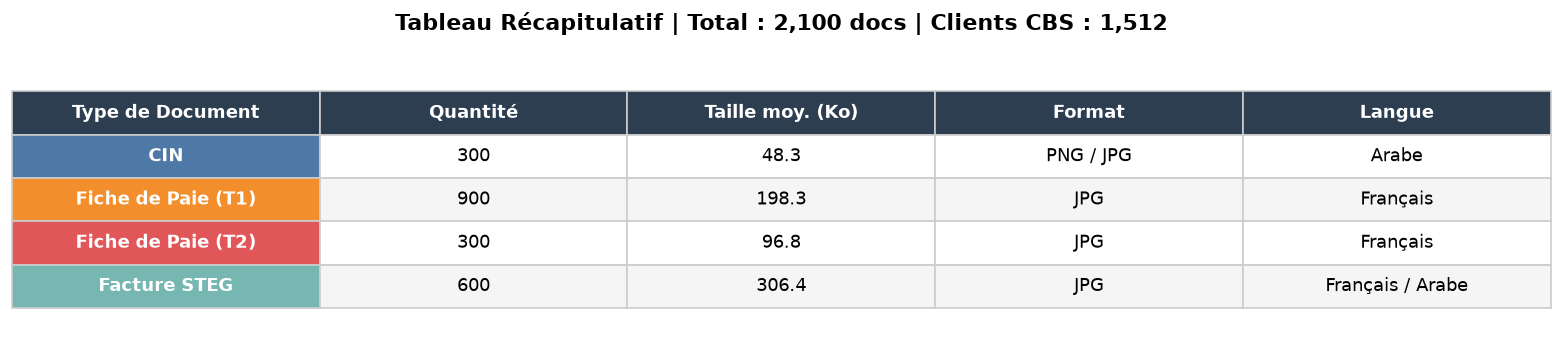

In [9]:
formats_info = {
    'CIN'               : ('PNG / JPG', 'Arabe'),
    'Fiche de Paie (T1)': ('JPG',       'Français'),
    'Fiche de Paie (T2)': ('JPG',       'Français'),
    'Facture STEG'      : ('JPG',       'Français / Arabe'),
}

col_labels = ['Type de Document', 'Quantité', 'Taille moy. (Ko)', 'Format', 'Langue']
rows = []
for t in counts.keys():
    taille_moy = f"{np.mean(tailles_ko[t]):.1f}" if tailles_ko[t] else 'N/A'
    fmt, lang  = formats_info.get(t, ('?', '?'))
    rows.append([t, f"{counts[t]:,}", taille_moy, fmt, lang])

fig, ax = plt.subplots(figsize=(13, 3))
ax.axis('off')
table = ax.table(cellText=rows, colLabels=col_labels, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2.2)

row_colors = [COLORS['cin'], COLORS['paie1'], COLORS['paie2'], COLORS['steg']]
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#CCCCCC')
    if row == 0:
        cell.set_facecolor('#2C3E50')
        cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#F5F5F5')
    else:
        cell.set_facecolor('white')
    if col == 0 and row > 0:
        cell.set_facecolor(row_colors[row - 1])
        cell.set_text_props(color='white', fontweight='bold')

ax.set_title(f'Tableau Récapitulatif | Total : {sum(counts.values()):,} docs | Clients CBS : {total_clients:,}',
             fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

---
## 5. Conclusions de la Phase Data Understanding

L'analyse exploratoire du jeu de données synthétique révèle les points clés suivants :

1. **Volume suffisant** : Le jeu de données comprend **2 100 documents** répartis sur 4 types, permettant une évaluation statistiquement significative du système.

2. **Diversité linguistique** : Les CIN sont rédigées en arabe, tandis que les Fiches de Paie sont en français. Le CBS contient les profils en **version bilingue** (Arabe + Français), ce qui permet de valider la capacité d'extraction bilingue du moteur OCR.

3. **Représentativité des risques** : La distribution des niveaux de risque (70% Faible, 20% Moyen, 10% Élevé) reflète les statistiques généralement observées dans le secteur bancaire.

4. **Données synthétiques justifiées** : En l'absence de données réelles (contrainte de **secret bancaire**), la génération synthétique à partir de templates réels et de la bibliothèque `Faker` garantit un niveau de réalisme suffisant pour valider les performances du pipeline OCR + Jaro-Winkler.

5. **Qualité homogène** : Les documents synthétiques présentent une qualité d'image contrôlée (pas de bruit, pas de déformation), ce qui constitue un cas optimal. Les tests sur des images réelles (photographiées, froissées) représentent le cas le plus difficile et constituent une perspective d'amélioration.